# 02 — Exploratory analysis, stationarity and pivot date

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 2 (no forecasting model yet).

| | |
|---|---|
| **Input** | `data/processed/panel.parquet` (frozen Phase 1 snapshot, never re-downloaded) |
| **Outputs** | `figures/fig_02_*.png`, `results/02_*.csv`, `pivot_date` in `config.yaml` (after validation) |
| **Brief** | §1.3 (chronological split), §2 (plots, ACF/PACF raw and differenced, decomposition, outliers, ADF + KPSS) |

Series studied: the two equal-weighted indices **CONVERTS** (IREN, CIFR, WULF) and **PURE** (MARA, CLSK, RIOT), and the two references **BTC** and **NVDA**.
The six individual stocks are added to the stationarity tests to check that the indices hide nothing.

Convention: every test states **H0**, the statistic, the p-value and a written conclusion at the 5% level.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from src import config, data, eda, plotting

SEED = config.set_seed()    # no randomness here, but the seed is fixed in every notebook for consistency
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
RES = config.path("results")
print("root:", ROOT.name, "| seed:", SEED)

root: Bitcoin miners | seed: 42


In [2]:
# Load ONLY the frozen snapshot of phase 1 (never the API), so every number below is reproducible.
panel = data.load_panel()
CORE = list(plotting.CORE)                       # CONVERTS, PURE, BTC, NVDA
MINERS = ["IREN", "CIFR", "WULF", "MARA", "CLSK", "RIOT"]
logp = pd.DataFrame({s: panel[f"{s}_log_price"] for s in CORE + MINERS})
ret = pd.DataFrame({s: panel[f"{s}_log_return"] for s in CORE + MINERS}).dropna()
rv = pd.DataFrame({s: panel[f"{s}_rv20"] for s in CORE})
train, test = data.chrono_split(panel)
print(f"{len(panel)} trading days, {panel.index[0].date()} -> {panel.index[-1].date()} | returns: {len(ret)}")

1225 trading days, 2021-12-14 -> 2026-10-30 | returns: 1224


## 1. Plotting the series

Four views: (a) log prices of the six miners, (b) indices and references rebased to 100, (c) log returns, (d) 20-day realised volatility.
A log scale is used for every price chart: the miners move by a factor of 10 to 50, and a linear scale would flatten the small values.

figures\fig_02_01_log_prices_miners.png


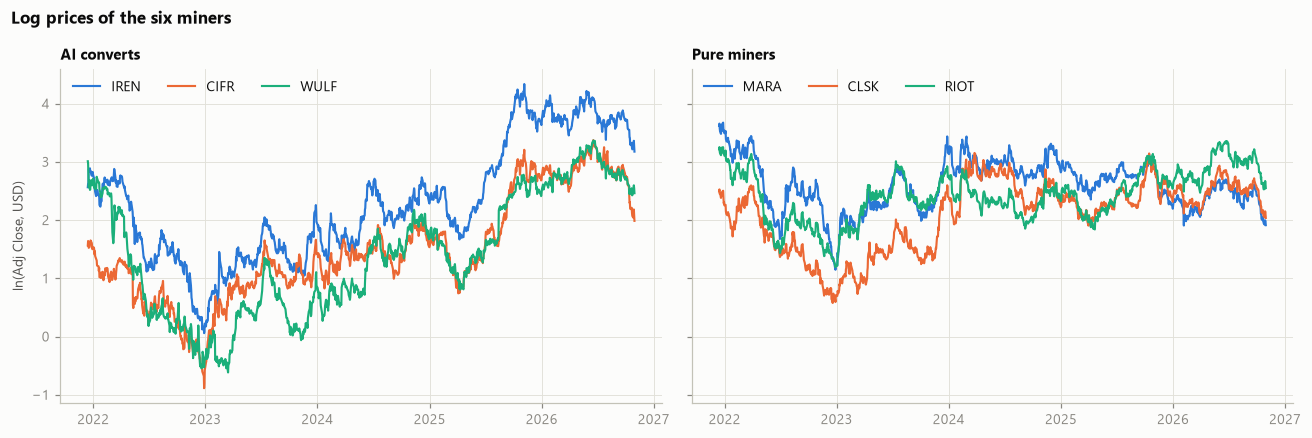

In [3]:
# Log prices per group: on a log axis equal vertical distances = equal % moves, so the six stocks are comparable.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, cols) in zip(axes, {"AI converts": MINERS[:3], "Pure miners": MINERS[3:]}.items()):
    for c, col in zip(cols, plotting.SERIES):
        ax.plot(logp.index, logp[c], color=col, label=c)
    ax.set_title(title); ax.legend(loc="upper left", ncol=3)
axes[0].set_ylabel("ln(Adj Close, USD)")
fig.suptitle("Log prices of the six miners", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); print(plotting.save(fig, "fig_02_01_log_prices_miners")); plt.show()

figures\fig_02_02_indices_vs_references.png


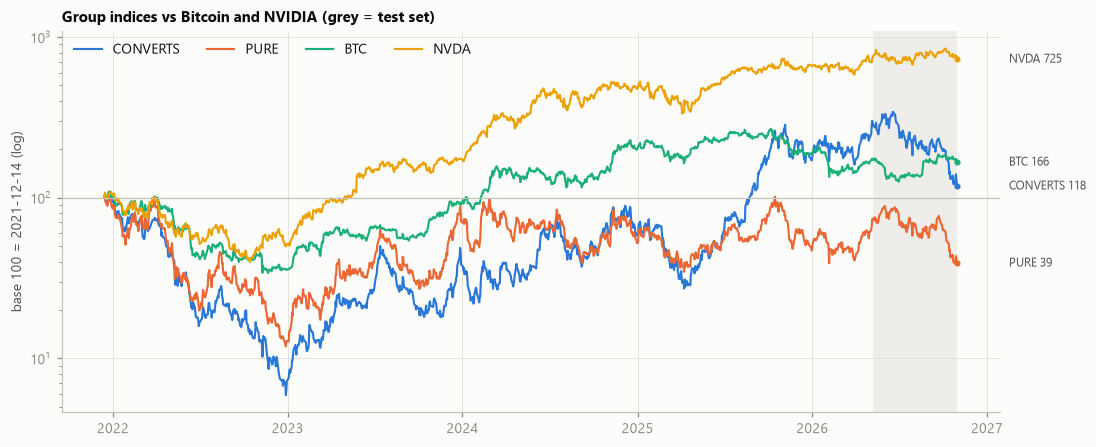

In [4]:
# Indices vs references on one base (100 on day 1): the direct visual version of the research question.
lvl = {"CONVERTS": panel["CONVERTS_level"], "PURE": panel["PURE_level"],
       "BTC": 100 * panel["BTC_adj_close"] / panel["BTC_adj_close"].iloc[0],
       "NVDA": 100 * panel["NVDA_adj_close"] / panel["NVDA_adj_close"].iloc[0]}
fig, ax = plt.subplots(figsize=(11, 4.5))
for k, s in lvl.items():
    ax.plot(s.index, s, color=plotting.CORE[k], label=k)
ax.axhline(100, color=plotting.AXIS, lw=0.8)
ax.axvspan(test.index[0], test.index[-1], color=plotting.GRID, alpha=0.5, lw=0)
ax.set_yscale("log"); ax.set_ylabel("base 100 = 2021-12-14 (log)"); ax.legend(loc="upper left", ncol=4)
ax.set_title("Group indices vs Bitcoin and NVIDIA (grey = test set)")
plotting.label_line_ends(ax, lvl, plotting.CORE)
print(plotting.save(fig, "fig_02_02_indices_vs_references")); plt.show()

figures\fig_02_03_log_returns.png


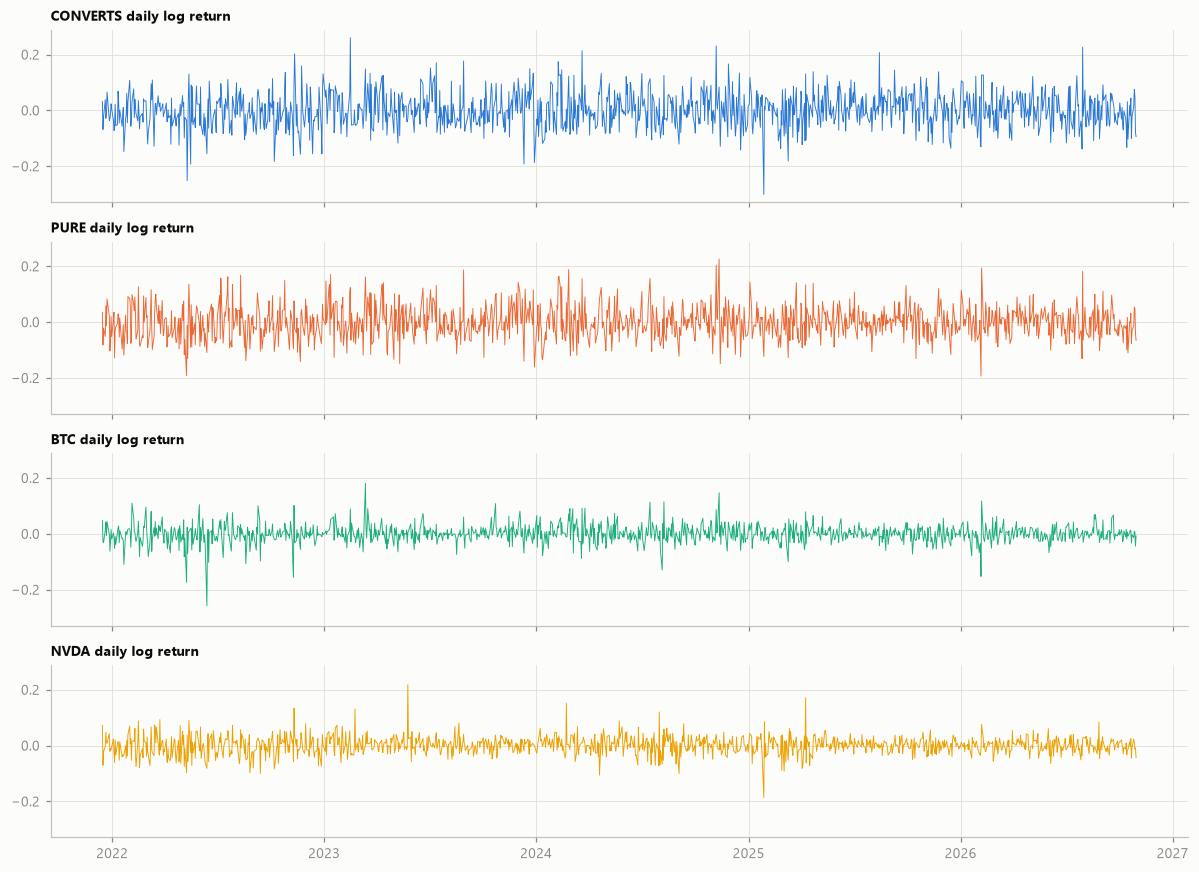

In [5]:
# Returns on a COMMON y-axis so the difference in scale between miners and references is visible at once.
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, s in zip(axes, CORE):
    ax.plot(ret.index, ret[s], color=plotting.CORE[s], lw=0.6)
    ax.set_title(f"{s} daily log return", fontsize=9)
fig.tight_layout(); print(plotting.save(fig, "fig_02_03_log_returns")); plt.show()

figures\fig_02_04_realised_vol20.png


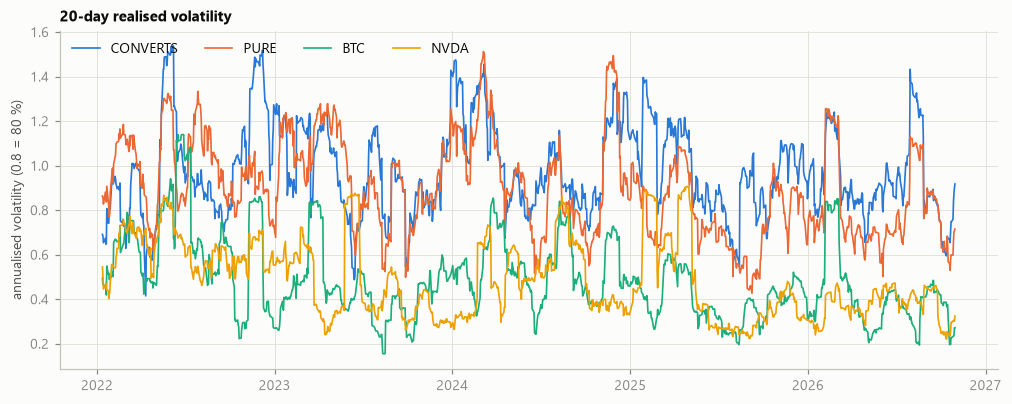

In [6]:
# 20-day realised volatility (annualised) shows volatility clustering, the first hint for GARCH (phase 5).
fig, ax = plt.subplots(figsize=(11, 4))
for s in CORE:
    ax.plot(rv.index, rv[s], color=plotting.CORE[s], label=s, lw=1.1)
ax.set_ylabel("annualised volatility (0.8 = 80 %)"); ax.legend(loc="upper left", ncol=4)
ax.set_title("20-day realised volatility")
print(plotting.save(fig, "fig_02_04_realised_vol20")); plt.show()

In [7]:
# Moments of returns: scale, asymmetry and tails decide later choices (Student-t GARCH, MAPE on prices, etc.).
def describe(r: pd.Series) -> dict:
    return {"n": r.size, "mean": r.mean(), "std": r.std(), "annualised vol": r.std() * np.sqrt(252),
            "skewness": r.skew(), "excess kurtosis": r.kurt(), "min": r.min(), "date min": r.idxmin().date(),
            "max": r.max(), "date max": r.idxmax().date()}
desc = pd.DataFrame({s: describe(ret[s]) for s in CORE}).T
desc.to_csv(RES / "02_descriptive_stats.csv")
desc

,n,mean,std,annualised vol,skewness,excess kurtosis,min,date min,max,date max
CONVERTS,1224,0.0001,0.0628,0.9977,0.1123,0.9518,-0.3006,2025-01-27,0.2606,2023-02-15
PURE,1224,-0.0008,0.0582,0.9235,0.3039,0.5889,-0.1929,2026-02-05,0.2261,2024-11-11
BTC,1224,0.0004,0.0324,0.515,-0.3405,6.5061,-0.2572,2022-06-13,0.1812,2023-03-13
NVDA,1224,0.0016,0.0322,0.5112,0.2414,3.9298,-0.1859,2025-01-27,0.2181,2023-05-25


**Reading the charts and the table.**

* **Scales.** The two miner indices are about twice as volatile as BTC and NVDA (daily std ≈ 6% vs ≈ 3.2%, i.e. annualised volatility close to 100% vs ≈ 51%). Comparing raw levels would make no sense: we work in logs and in returns.
* **Trends.** NVDA has an almost continuous uptrend. BTC falls in 2022, then rises strongly from 2023. PURE ends **below** its base of 100 (≈ 39) while CONVERTS ends above it (≈ 118) after a peak at ≈ 343: the two groups move together until mid-2025, then clearly **diverge**: CONVERTS takes off in summer 2025 while PURE stagnates. This is the observation behind the research question.
* **Visible breaks.** The 2022 crash (all assets), a strong common rise in late 2023 / early 2024, CONVERTS breaking away upwards from August 2025, and a sharp fall of both indices at the end of the sample; the test period (grey area) lies in the most recent regime.
* **Shape of returns.** Daily means are indistinguishable from 0 relative to the std. Excess kurtosis is high for BTC (≈ 6.5) and NVDA (≈ 3.9), lower for the indices (≈ 0.6–1) because averaging three stocks smooths individual tails. Realised volatility shows **clusters** (calm and turbulent periods following each other): conditional heteroscedasticity is likely, to be tested in Phase 5.

## 2. ACF and PACF — raw series (log price), then differenced (returns)

Bands: 95% confidence interval under H0 "white noise" (≈ ±1.96/√n ≈ ±0.056 for n = 1,224).

figures\fig_02_05_acf_pacf_log_price.png


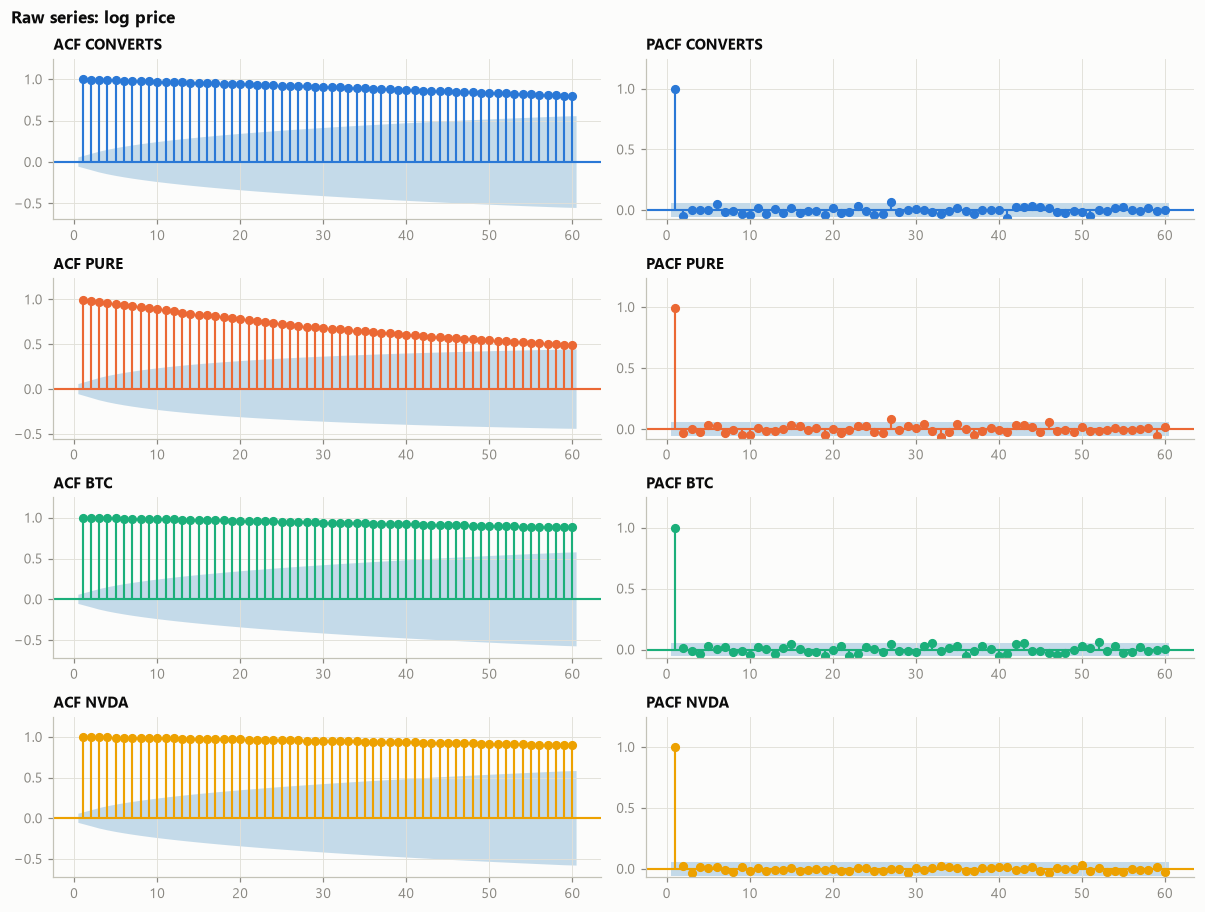

        CONVERTS   PURE    BTC   NVDA
lag 1      0.997  0.989  0.998  0.999
lag 10     0.973  0.890  0.982  0.985
lag 20     0.942  0.779  0.963  0.970
lag 60     0.800  0.488  0.880  0.898


In [8]:
# Raw series first: a slow, almost linear ACF decay is the classic signature of a unit root.
def acf_grid(df: pd.DataFrame, lags: int, title: str, name: str):
    fig, axes = plt.subplots(len(df.columns), 2, figsize=(11, 2.1 * len(df.columns)))
    for i, s in enumerate(df.columns):
        plot_acf(df[s].dropna(), lags=lags, ax=axes[i, 0], zero=False, color=plotting.CORE[s],
                 vlines_kwargs={"colors": plotting.CORE[s]}, title=f"ACF {s}", auto_ylims=True)
        plot_pacf(df[s].dropna(), lags=lags, ax=axes[i, 1], zero=False, method="ywm", color=plotting.CORE[s],
                  vlines_kwargs={"colors": plotting.CORE[s]}, title=f"PACF {s}", auto_ylims=True)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold"); fig.tight_layout()
    print(plotting.save(fig, name)); plt.show()

acf_grid(logp[CORE], 60, "Raw series: log price", "fig_02_05_acf_pacf_log_price")
from statsmodels.tsa.stattools import acf, pacf
print(pd.DataFrame({s: acf(logp[s], nlags=60)[[1, 10, 20, 60]] for s in CORE}, index=["lag 1", "lag 10", "lag 20", "lag 60"]).round(3))

**Interpretation — log prices.** For all four series, the ACF starts at about 0.99–1.00 at lag 1 and decays **very slowly and almost linearly** (it stays far above the band at 60 lags). The PACF has a single spike at lag 1, close to 1, and nothing after. This is the signature of a **unit root** (random walk): each price "remembers" almost all of its past. These charts do not allow reading p and q; they only say that we must **difference** (d ≥ 1), which the ADF/KPSS tests of section 5 will confirm formally.

figures\fig_02_06_acf_pacf_log_return.png


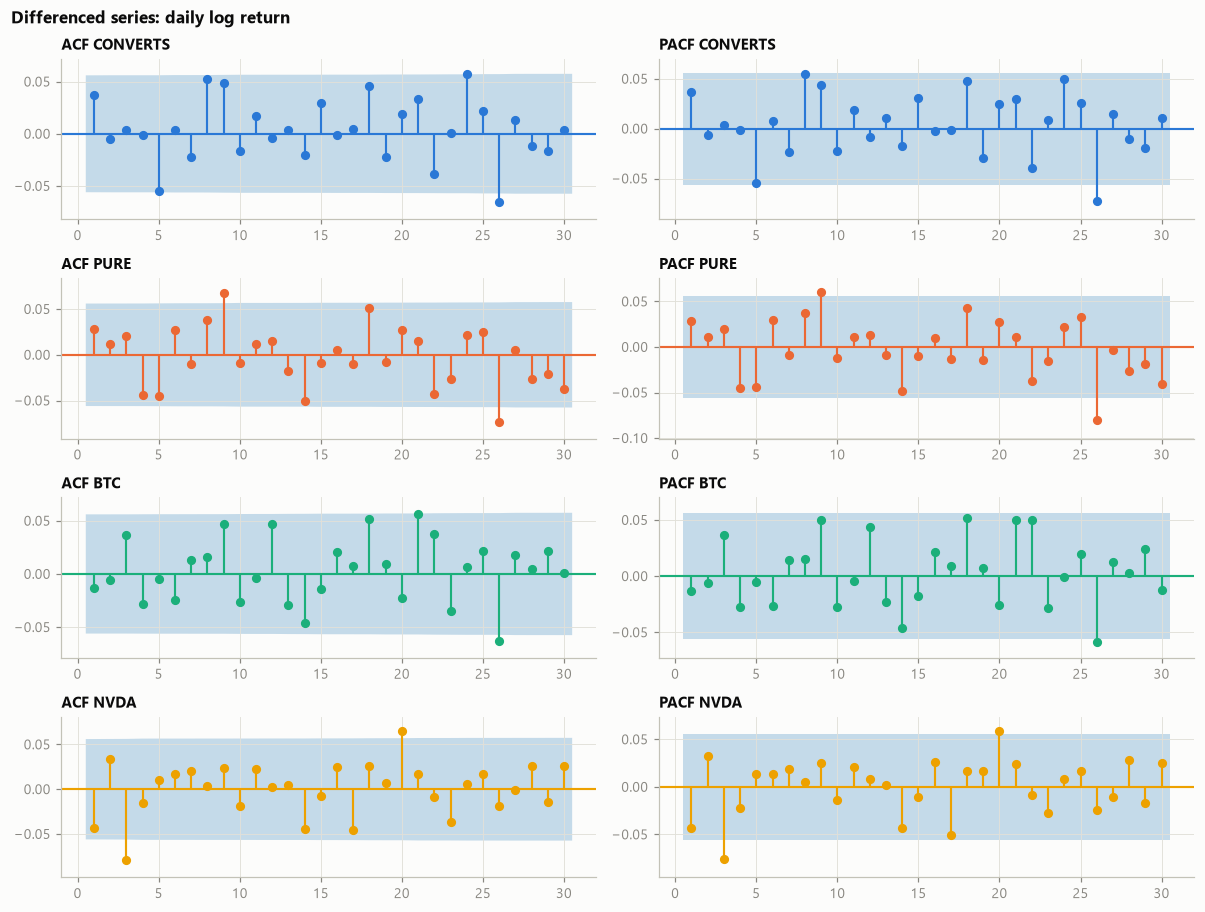

band ±0.056 | lags outside the band (ACF, 1-30): {'CONVERTS': [24, 26], 'PURE': [9, 26], 'BTC': [21, 26], 'NVDA': [3, 20]}


In [9]:
# Differenced series: once the unit root is removed, any remaining spike would suggest an AR/MA term.
acf_grid(ret[CORE], 30, "Differenced series: daily log return", "fig_02_06_acf_pacf_log_return")
band = 1.96 / np.sqrt(len(ret))
sig = {s: [k for k, v in enumerate(acf(ret[s], nlags=30)[1:], 1) if abs(v) > band] for s in CORE}
print(f"band ±{band:.3f} | lags outside the band (ACF, 1-30):", sig)

In [10]:
# Ljung-Box on returns (H0: no autocorrelation up to lag m) and on squared returns (H0: no ARCH-type dependence).
lb = []
for s in CORE:
    for what, x in [("return", ret[s]), ("rendement²", ret[s] ** 2)]:
        t = acorr_ljungbox(x, lags=[5, 10, 20])
        for m, row in t.iterrows():
            lb.append({"series": s, "variable": what, "lag": m, "Q": row["lb_stat"], "p_value": row["lb_pvalue"],
                       "conclusion": "reject H0 (dependence)" if row["lb_pvalue"] < 0.05 else "H0 not rejected"})
lb = pd.DataFrame(lb)
lb.to_csv(RES / "02_ljungbox_returns.csv", index=False)
lb.pivot_table(index=["series", "variable"], columns="lag", values="p_value", sort=False).round(4)

lag                      5       10      20
series   variable                          
CONVERTS return      0.3667  0.2416  0.5674
         rendement²  0.5040  0.8511  0.8462
PURE     return      0.2519  0.1317  0.2687
         rendement²  0.0027  0.0005  0.0018
BTC      return      0.7118  0.6499  0.5125
         rendement²  0.0036  0.0095  0.0662
NVDA     return      0.0385  0.1851  0.1553
         rendement²  0.0128  0.0537  0.1353

**Interpretation — returns.**

* **ACF/PACF of returns.** At the first lags, all autocorrelations are inside the ±0.056 band. A few isolated lags barely exceed it (CONVERTS: 24 and 26; PURE: 9 and 26; BTC: 21 and 26; NVDA: 3 and 20). With 30 lags tested at 5%, we expect ≈ 1.5 exceedances per series by pure chance: these spikes form no interpretable pattern (no clear cut-off of the ACF or PACF).
* **Ljung-Box on returns** (H0: no autocorrelation up to lag m). CONVERTS: p = 0.37 / 0.24 / 0.57 (m = 5 / 10 / 20); PURE: 0.25 / 0.13 / 0.27; BTC: 0.71 / 0.65 / 0.51 → **H0 is not rejected**: the returns of these three series cannot be predicted linearly from their past. NVDA: p = 0.0385 at m = 5 (rejected at 5%, driven by lag 3, ACF = −0.079), but 0.19 and 0.16 at m = 10 and 20 → weak, short dependence.
* **Consequence for p and q.** For CONVERTS (main target) and PURE, nothing suggests an AR or MA term: the natural candidate is **ARIMA(0,1,0)** on the log price (random walk, possibly with drift), with at most a small ARMA(1,1) to compare in Phase 3. For NVDA, a term of order ≤ 3 could be tested.
* **Ljung-Box on squared returns** (H0: no dependence in the variance). Clear rejection for PURE (p ≤ 0.0027 at all three lags), BTC (p = 0.0036 and 0.0095 at m = 5 and 10) and NVDA (p = 0.0128 at m = 5) → **volatility clusters**, which motivates the GARCH models of Phase 5. For CONVERTS, however, p = 0.50 / 0.85 / 0.85: no linear dependence is detected in the squares, even though realised volatility (fig. 02_04) visibly changes over time. To be re-checked with the ARCH-LM test on the ARIMA residuals (Phase 3): a few very large isolated jumps can hide the effect in the autocorrelations of the squares.

## 3. STL decomposition

STL (Seasonal-Trend decomposition using Loess) on the **log price**, robust version (isolated crashes do not contaminate the seasonal component). Two periods tested:
* **s = 5**: trading week (day-of-week effect);
* **s = 252**: trading year (annual calendar effect). With 1,225 observations there are only ≈ 4.9 annual cycles: the estimate is fragile, keep it in mind.

Measures (FPP3, §3.9): seasonal strength **F_S = max(0, 1 − Var(R) / Var(S+R))** and trend strength **F_T = max(0, 1 − Var(R) / Var(T+R))**, between 0 (absent) and 1 (dominant). The share of each component in the total variance is also given.

In [11]:
# Fit both periods for the four series and keep only the summary numbers (the full fits are plotted for CONVERTS).
stl_rows, stl_fits = [], {}
for s in CORE:
    for per in (5, 252):
        d = eda.stl_shares(logp[s], per)
        stl_fits[(s, per)] = d.pop("result")
        stl_rows.append({"series": s, **d})
stl_tab = pd.DataFrame(stl_rows)
stl_tab.to_csv(RES / "02_stl_seasonality.csv", index=False)
stl_tab.round(4)

,series,period,var_share_seasonal,var_share_remainder,seasonal_strength_FS,trend_strength_FT,seasonal_amplitude
0,CONVERTS,5,0.0006,0.0034,0.0093,0.9966,0.1710
1,CONVERTS,252,0.1573,0.2268,0.0000,0.7999,2.3366
2,PURE,5,0.0027,0.0137,0.0297,0.9863,0.1779
3,PURE,252,0.6118,0.7808,0.0000,0.2988,2.0128
4,BTC,5,0.0003,0.0024,0.0163,0.9976,0.0923
5,BTC,252,0.2271,0.2423,0.0397,0.7854,1.4382
6,NVDA,5,0.0002,0.0009,0.0000,0.9991,0.1068
7,NVDA,252,0.0666,0.0673,0.1146,0.9389,1.5084


figures\fig_02_07_stl_converts_s5.png


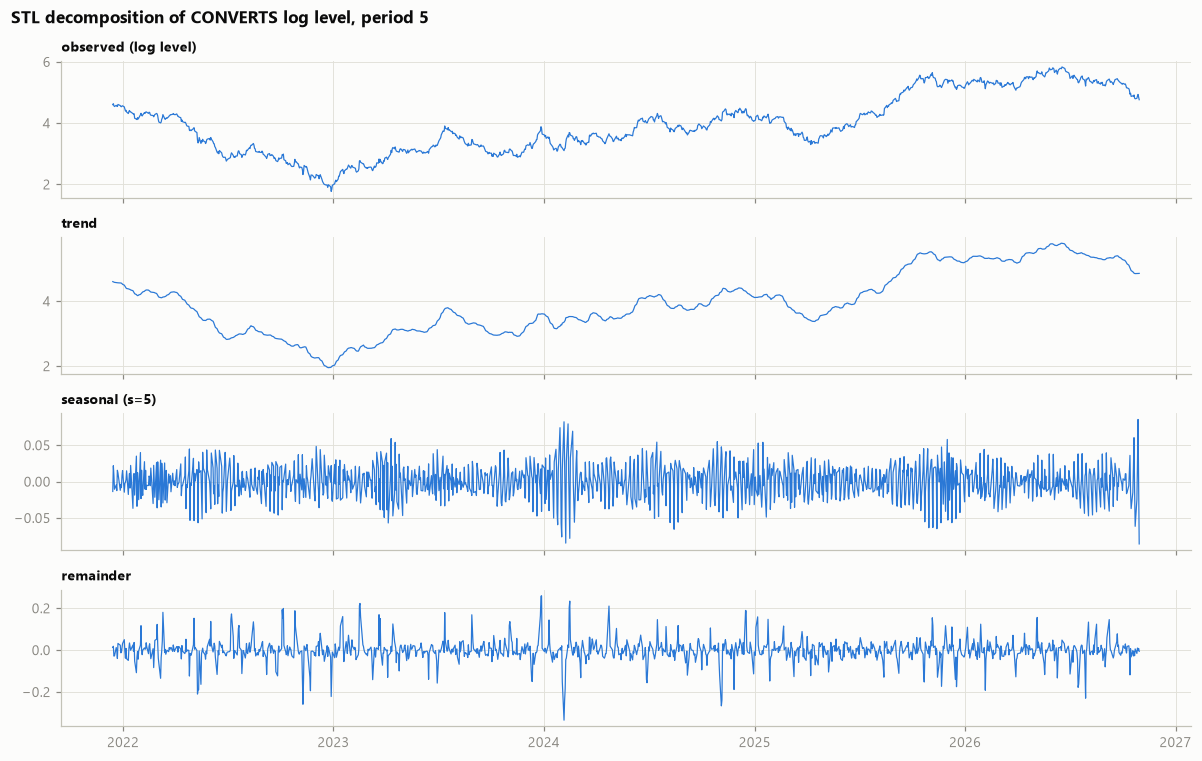

figures\fig_02_08_stl_converts_s252.png


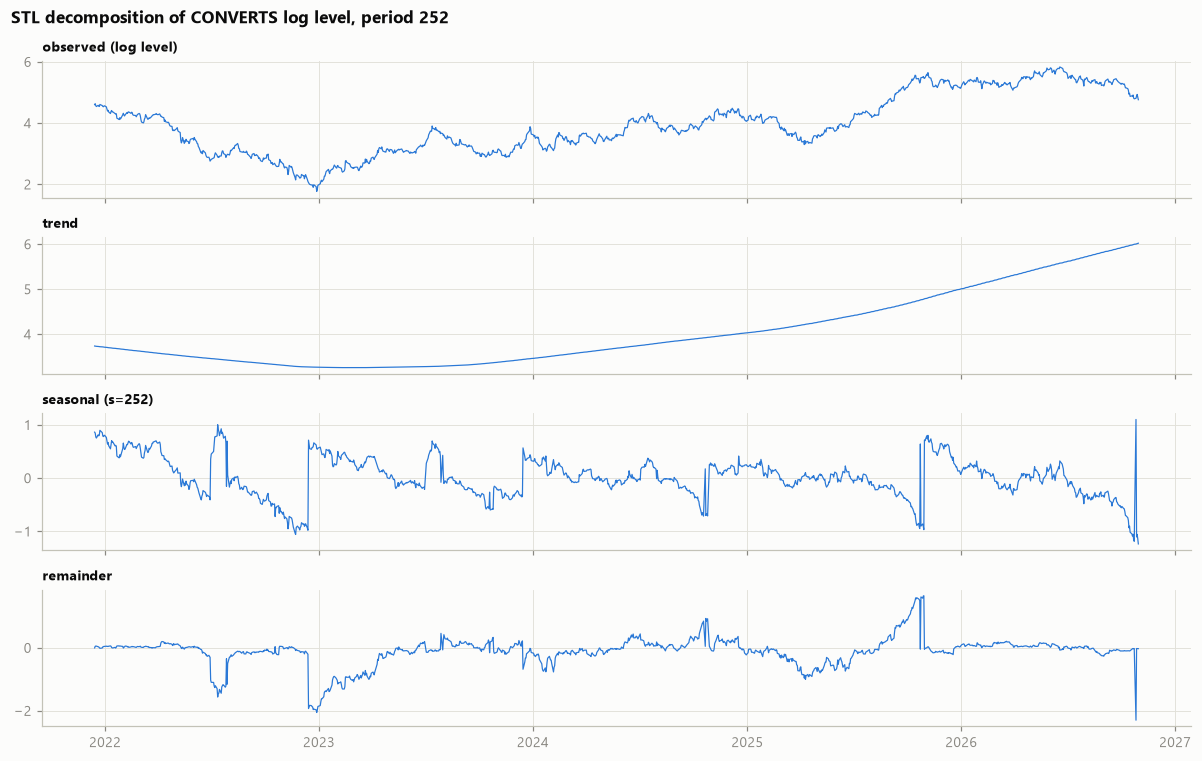

In [12]:
# Component plots for the main series (CONVERTS), one figure per period, to read trend / seasonal / remainder.
for per, name in [(5, "fig_02_07_stl_converts_s5"), (252, "fig_02_08_stl_converts_s252")]:
    res = stl_fits[("CONVERTS", per)]
    comps = {"observed (log level)": logp["CONVERTS"].to_numpy(), "trend": res.trend, f"seasonal (s={per})": res.seasonal, "remainder": res.resid}
    fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
    for ax, (k, v) in zip(axes, comps.items()):
        ax.plot(logp.index, v, color=plotting.CORE["CONVERTS"], lw=0.8); ax.set_title(k, fontsize=9)
    fig.suptitle(f"STL decomposition of CONVERTS log level, period {per}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); print(plotting.save(fig, name)); plt.show()

In [13]:
# Direct test of a weekly pattern on RETURNS (the series ARIMA will model): is the mean return different by weekday?
wk = pd.DataFrame({s: eda.weekday_effect(ret[s]) for s in CORE}).T
wk.to_csv(RES / "02_weekday_effect.csv")
wk

,anova_F,anova_p,kruskal_H,kruskal_p,mean_mon,mean_fri,share_var_explained
CONVERTS,0.6720,0.6114,3.9346,0.4149,0.0017,0.0024,0.0022
PURE,0.8446,0.4969,2.6532,0.6174,0.0038,-0.0025,0.0028
BTC,1.2477,0.2889,6.5822,0.1597,0.0031,-0.0006,0.0041
NVDA,1.3168,0.2616,8.1054,0.0878,0.0036,-0.0023,0.0043


**Interpretation of the decomposition.**

* **Period 5 (week).** Seasonal strength F_S is between 0 and 0.03 for the four series, and the seasonal component accounts for at most 0.27% of total variance (0.06% for CONVERTS). Trend strength F_T is ≥ 0.986: the log price is almost entirely "trend + noise". In fig. 02_07, the seasonal component of CONVERTS keeps changing shape: it follows the noise, not a repeated pattern.
* **Period 252 (year).** F_S = 0 for CONVERTS and PURE, 0.04 for BTC and 0.11 for NVDA. Yet the "seasonal" component takes 7 to 61% of the variance: with only ≈ 4.9 cycles, STL puts the large multi-month waves there (2022 crash, 2024–2025 rise), which do not repeat from one year to the next. Trend strength drops accordingly (0.30 for PURE). This is not seasonality, it is the market cycle arbitrarily cut into 252-day slices.
* **Direct test on returns (day-of-week effect).** H0: same mean return on every weekday. ANOVA: p = 0.61 (CONVERTS), 0.50 (PURE), 0.29 (BTC), 0.26 (NVDA); Kruskal-Wallis (no normality assumption): p = 0.41; 0.62; 0.16; 0.09. **H0 is never rejected at 5%**, and the weekday explains at most 0.43% of the variance of returns.
* **Remainder.** It contains the crashes and jumps (2022, 2025): that is where the information is, not in seasonality.
* **Conclusion: there is no real seasonality** (neither weekly nor annual) in these series. A SARIMA is therefore not justified; Phase 3 checks this formally but starts from this evidence.

## 4. Outliers in returns

Two complementary rules, applied to returns (prices are not stationary, so a fixed rule would make no sense on them):
* **Hampel filter** (centred 21-day window, threshold 4 robust standard deviations = 4 × 1.4826 × MAD). The median and MAD are not pulled by the extreme values themselves. Threshold 4 rather than 3: financial returns have fat tails, and a threshold of 3 would flag dozens of ordinary days.
* **Rolling box plot** (IQR over the **previous** 63 days, ≈ 1 quarter, Tukey's "far out" k = 3): what an observer would have judged abnormal on the day itself.

Associated events are given only when they are obvious; two dates were checked in the press (sources at the end of the section), the others are widely known market facts. Dates with no clear link are marked "not identified": no cause is invented.

In [14]:
# Flag with both rules, keep the union, and record which rule fired so the table shows how robust each flag is.
EVENTS = {   # only obvious, well-documented market events; 2025-08-14 and 2026-02-05/06 checked in the press
    "2022-05-09": "Terra/LUNA collapse", "2022-05-10": "Terra/LUNA collapse",
    "2022-06-13": "Celsius freezes withdrawals (crypto credit crisis)",
    "2022-11-08": "FTX bankruptcy", "2022-11-09": "FTX bankruptcy",
    "2022-11-10": "rebound after lower-than-expected US inflation (CPI)",
    "2023-03-13": "SVB / USDC weekend, US deposit guarantee",
    "2023-05-25": "NVDA earnings (record AI guidance)", "2024-02-22": "NVDA earnings",
    "2024-08-05": "global crash (yen carry-trade unwind)",
    "2024-11-06": "US presidential election", "2024-11-11": "post-election rally; for PURE, includes the carry-over from 2024-11-08 (CLSK placeholder row, Phase 1)",
    "2025-01-27": "DeepSeek shock (NVDA -17% intraday)",
    "2025-08-14": "TeraWulf-Fluidstack deal backstopped by Google (AI/HPC)",
    "2026-02-05": "BTC falls below $70,000", "2026-02-06": "BTC rebound after the fall",
}
rows = []
for s in CORE:
    h, q = eda.hampel(ret[s]), eda.rolling_iqr(ret[s])
    for d in ret.index[h["flag"] | q["flag"]]:
        rows.append({"date": d.date(), "series": s, "return": ret.at[d, s], "score_hampel": h.at[d, "score"],
                     "hampel": bool(h.at[d, "flag"]), "rolling_iqr": bool(q.at[d, "flag"]),
                     "event": EVENTS.get(str(d.date()), "not identified")})
outl = pd.DataFrame(rows).sort_values(["date", "series"]).reset_index(drop=True)
outl.to_csv(RES / "02_outliers.csv", index=False)
print(outl.groupby("series", sort=False)[["hampel", "rolling_iqr"]].sum().assign(total=outl.groupby("series", sort=False).size()))
outl

          hampel  rolling_iqr  total
series                              
BTC           22           14     26
CONVERTS      11            1     12
NVDA           7            3      7
PURE          10            2     11


,date,series,return,score_hampel,hampel,rolling_iqr,event
0,2022-01-21,BTC,-0.1096,-5.3074,True,False,not identified
1,2022-02-04,BTC,0.1106,5.9859,True,False,not identified
2,2022-03-14,CONVERTS,-0.1280,-5.1101,True,False,not identified
3,2022-05-09,BTC,-0.1736,-4.3485,True,True,Terra/LUNA collapse
4,2022-05-10,CONVERTS,-0.2514,-2.8843,False,True,Terra/LUNA collapse
5,2022-06-13,BTC,-0.2572,-6.9370,True,True,Celsius freezes withdrawals (crypto credit cri...
6,2022-08-19,BTC,-0.1060,-4.6496,True,False,not identified
7,2022-09-09,BTC,0.1009,4.4792,True,False,not identified
8,2022-09-13,BTC,-0.0973,-4.0795,True,False,not identified
9,2022-11-08,BTC,-0.1054,-3.0640,False,True,FTX bankruptcy


figures\fig_02_09_outliers_returns.png


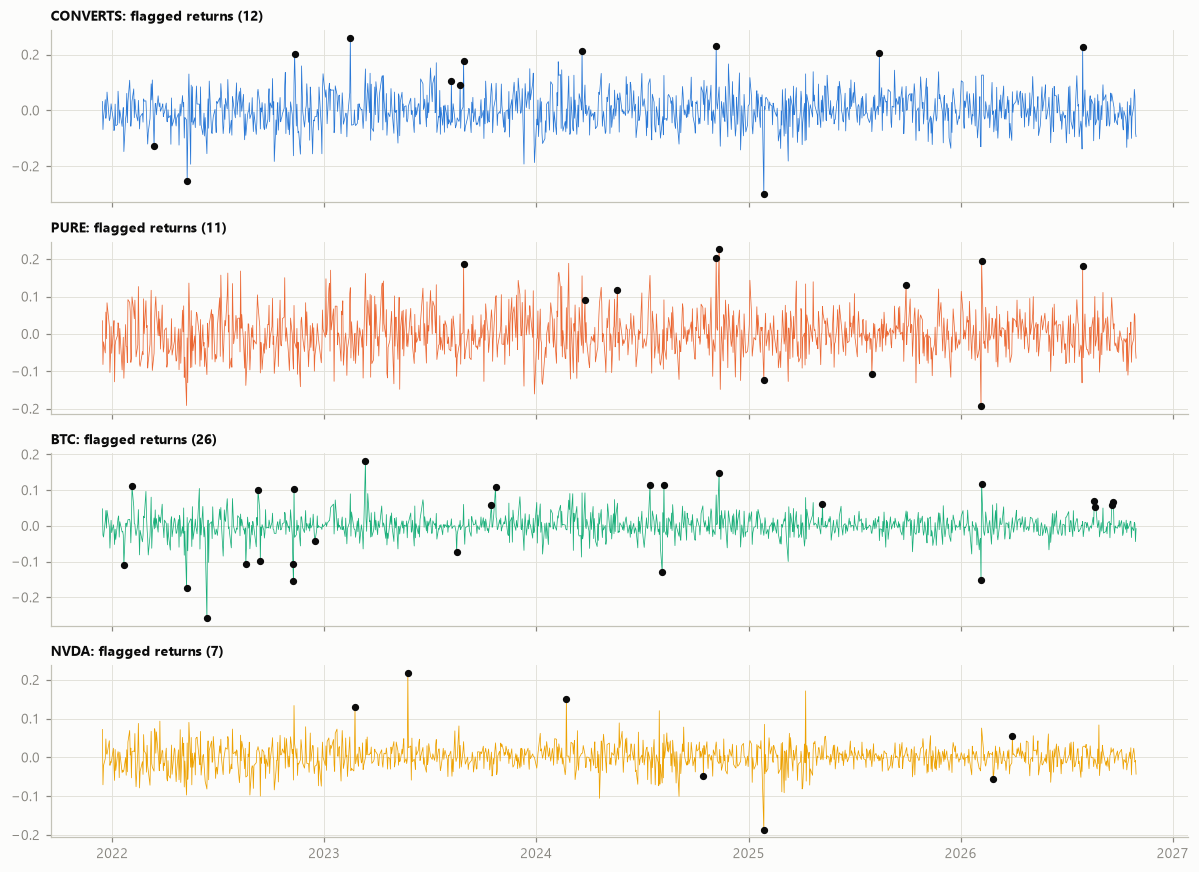

In [15]:
# Plot the flags on the returns so the reader sees they sit inside volatile clusters, not as isolated data errors.
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, s in zip(axes, CORE):
    ax.plot(ret.index, ret[s], color=plotting.CORE[s], lw=0.5)
    f = outl[outl["series"] == s]
    ax.scatter(pd.to_datetime(f["date"]), f["return"], s=14, color=plotting.INK, zorder=3)
    ax.set_title(f"{s}: flagged returns ({len(f)})", fontsize=9)
fig.tight_layout(); print(plotting.save(fig, "fig_02_09_outliers_returns")); plt.show()

**Chosen treatment: keep them (no winsorising, no correction).**

* **Number of flagged days** (union of both rules): CONVERTS 12, PURE 11, BTC 26, NVDA 7. Hampel is more sensitive than the rolling box plot because it compares with the immediate neighbourhood; together the two rules mostly flag BTC.
* **Identified events**: the 2022 crypto crises (Terra/LUNA, Celsius, FTX), the SVB weekend (March 2023), NVDA earnings (May 2023, February 2024), the August 2024 crash, the US election (November 2024), the DeepSeek shock (2025-01-27), the TeraWulf–Google deal (2025-08-14, CONVERTS log return +0.21), and the BTC fall in February 2026. Many days remain "not identified": no cause is attributed to them.
* **A useful clue for the research question**: on 2025-01-27 (DeepSeek, an **AI** shock, not a crypto one), the CONVERTS log return is −0.30 (its worst day in the sample) and NVDA's is −0.19, against only −0.12 for PURE. As early as January 2025, the converts react much more than the pure miners to AI news.
* **Why keep them?** (1) They are real market moves, not data errors. The only known data anomaly (the CLSK placeholder row of 2024-11-08) was already handled in Phase 1: the PURE return on 2024-11-11 covers two days, but the total move is real. (2) Winsorising would artificially reduce volatility and tails, and so distort the GARCH models (Phase 5, Student-t) and the forecast intervals. (3) Several of these days carry precisely the information about the pivot (DeepSeek, the Google deal): "correcting" them would erase what we want to measure.
* **Dummy variable**: `results/02_outliers.csv` keeps the dates. In Phase 3, an ARIMA with dummies on the largest shocks is tested only as a robustness check, not as the main model.

*Sources (checked on 2026-11-12):* TeraWulf / Google — [The Block](https://www.theblock.co/post/366959/bitcoin-miner-terawulf-shares-jump-50-after-google-secures-8-stake-as-part-of-3-7-billion-10-year-ai-compute-deal), [Motley Fool, 14/08/2025](https://www.fool.com/investing/2025/08/14/why-terawulf-stock-is-skyrocketing-today); BTC February 2026 — [The Block](https://www.theblock.co/post/388759/bitcoin-sees-flash-crash-60000), [Bloomberg, 05/02/2026](https://www.bloomberg.com/news/videos/2026-02-05/bitcoin-crashes-below-70-000-as-collapse-continues-video).

## 5. Stationarity: ADF and KPSS

* **ADF** — H0: the series has a unit root (non-stationary). Rejected if p < 0.05. Lags chosen by AIC.
* **KPSS** — H0: the series is stationary (around a constant or a trend). Rejected if p < 0.05.
* The two null hypotheses are opposite: if ADF rejects **and** KPSS does not → stationary; if ADF does not reject **and** KPSS rejects → non-stationary; otherwise ambiguous.
* Level (log price) tested **with constant and trend** (`ct`): a price can drift, so the alternative must allow it. Difference (return) tested **with constant** (`c`): a return has no trend.
* KPSS p-values are interpolated in a table bounded to [0.01, 0.10]: "0.01" reads "≤ 0.01", "0.10" reads "≥ 0.10".

In [16]:
# Run both tests on all 10 series (4 modelled + 6 individual stocks) in level and in first difference.
stat = eda.stationarity_table({s: logp[s] for s in CORE + MINERS})
stat.to_csv(RES / "02_stationarity_adf_kpss.csv", index=False)
stat[["series", "form", "adf_stat", "adf_p", "adf_lags", "kpss_stat", "kpss_p", "verdict"]].round(4)

,series,form,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,verdict
0,CONVERTS,level (log price),-2.9772,0.1386,0,0.7135,0.0100,non-stationary
1,CONVERTS,difference (log return),-33.6528,0.0000,0,0.2792,0.1000,stationary
2,PURE,level (log price),-3.2233,0.0799,0,0.2902,0.0100,non-stationary
3,PURE,difference (log return),-33.9517,0.0000,0,0.0979,0.1000,stationary
4,BTC,level (log price),-2.0654,0.5654,0,0.6049,0.0100,non-stationary
5,BTC,difference (log return),-35.4448,0.0000,0,0.1986,0.1000,stationary
6,NVDA,level (log price),-1.9916,0.6060,3,0.6100,0.0100,non-stationary
7,NVDA,difference (log return),-21.5484,0.0000,2,0.1833,0.1000,stationary
8,IREN,level (log price),-2.5182,0.3189,0,0.7768,0.0100,non-stationary
9,IREN,difference (log return),-34.5867,0.0000,0,0.1724,0.1000,stationary


In [17]:
# One line per series: the integration order d that ARIMA / VAR / VECM will use.
order = eda.integration_order(stat)
order.to_csv(RES / "02_integration_order.csv", index=False)
order

,series,level,difference,chosen d
0,CONVERTS,non-stationary,stationary,1
1,PURE,non-stationary,stationary,1
2,BTC,non-stationary,stationary,1
3,NVDA,non-stationary,stationary,1
4,IREN,non-stationary,stationary,1
5,CIFR,non-stationary,stationary,1
6,WULF,ambiguous (tests disagree),stationary,1
7,MARA,non-stationary,stationary,1
8,CLSK,non-stationary,stationary,1
9,RIOT,ambiguous (tests disagree),stationary,1


**Conclusion on the order of integration.**

* **Log prices (level).** For the four modelled series, ADF does not reject the unit root (p = 0.14 CONVERTS; 0.080 PURE; 0.57 BTC; 0.61 NVDA), and KPSS rejects stationarity (p ≤ 0.01 everywhere). Both tests agree: **non-stationary**.
* **Returns (first difference).** ADF rejects the unit root very strongly (statistics from −21.5 to −35.4, p < 0.001), and KPSS does not reject stationarity (p ≥ 0.10). Both tests agree: **stationary**.
* **Order of integration: d = 1 for all ten series.** Log prices are I(1) and returns I(0), as expected.
* **Borderline cases, reported honestly.**
  * PURE in level: ADF (p = 0.080) would be rejected at 10% but not at 5%, and KPSS rejects. It stays non-stationary.
  * **WULF and RIOT in level** are "ambiguous": ADF rejects at 5% (p = 0.037 and 0.034, against a stationary alternative **around a trend**), but KPSS also rejects (p ≤ 0.01). We keep **d = 1**, for three reasons. KPSS rejects clearly while ADF is just below the threshold. The ACF of the level decays slowly. And these two stocks enter the models only through the indices, which are clearly I(1).
  * WULF in difference: KPSS p = 0.054, so stationary by a narrow margin.
* **Consequences for what follows.** ARIMA(p,1,q) on the log price is an ARMA(p,q) on returns (Phase 3). Since all series are I(1), cointegration (Johansen, Engle-Granger, VECM) on log prices is legitimate (Phase 4). The VAR is estimated on returns, which are I(0).

## 6. Pivot date: detection from the data

The date is **not** taken from the news: we look for where the CONVERTS–BTC relationship changes. Three families of evidence, each with a **control group** (PURE): a change that also affects PURE is a "miners in general" change, not an AI pivot.

1. 120-day rolling correlation of CONVERTS (and PURE) with BTC and with NVDA.
2. Rolling Engle-Granger p-value (250-day window ≈ 1 year, recomputed every 5 days) on log prices.
3. Structural-break tests on the return regression **r_CONVERTS = a + b·r_BTC (+ c·r_NVDA) + e**: Chow scan (F statistic at each candidate date, 15% trimming at both ends) and Bai-Perron-style multiple breaks (dynamic programming with `ruptures`, number of breaks chosen by BIC).

figures\fig_02_10_rolling_corr_120.png


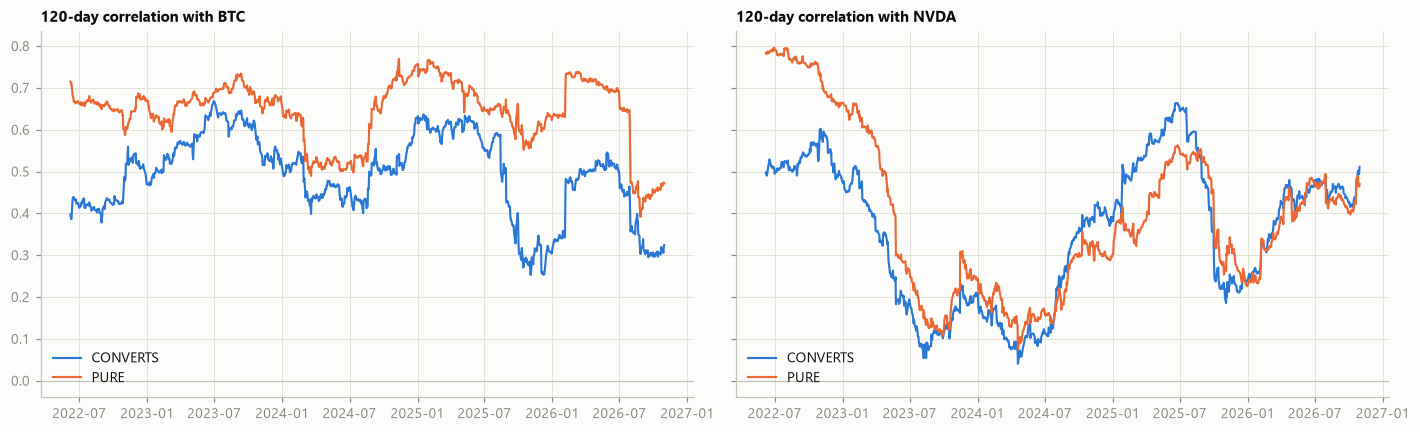

            CONVERTS~BTC  CONVERTS~NVDA  PURE~BTC  PURE~NVDA  gap CONVERTS-PURE ~BTC  gap CONVERTS-PURE ~NVDA
Date                                                                                                         
2022-06-30          0.42           0.50      0.66       0.80                   -0.24                    -0.29
2022-09-30          0.42           0.54      0.64       0.75                   -0.22                    -0.21
2022-12-31          0.47           0.48      0.67       0.66                   -0.20                    -0.19
2023-03-31          0.57           0.36      0.67       0.56                   -0.09                    -0.20
2023-06-30          0.67           0.19      0.69       0.27                   -0.02                    -0.07
2023-09-30          0.61           0.10      0.69       0.11                   -0.08                    -0.01
2023-12-31          0.53           0.20      0.67       0.24                   -0.14                    -0.04
2024-03-31

In [18]:
# 120-day rolling correlations: long enough to be stable, short enough to see a change within a year.
W = 120
rc = pd.DataFrame({f"{g}~{ref}": eda.rolling_corr(ret[g], ret[ref], W) for g in ("CONVERTS", "PURE") for ref in ("BTC", "NVDA")})
rc["gap CONVERTS-PURE ~BTC"] = rc["CONVERTS~BTC"] - rc["PURE~BTC"]
rc["gap CONVERTS-PURE ~NVDA"] = rc["CONVERTS~NVDA"] - rc["PURE~NVDA"]
rc.to_csv(RES / "02_rolling_corr_120.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, ref in zip(axes, ("BTC", "NVDA")):
    for g in ("CONVERTS", "PURE"):
        ax.plot(rc.index, rc[f"{g}~{ref}"], color=plotting.CORE[g], label=g)
    ax.axhline(0, color=plotting.AXIS, lw=0.8); ax.set_title(f"120-day correlation with {ref}"); ax.legend(loc="lower left")
fig.tight_layout(); print(plotting.save(fig, "fig_02_10_rolling_corr_120")); plt.show()
print(rc.resample("QE").last().round(2).loc["2022-06":])

figures\fig_02_11_rolling_engle_granger.png


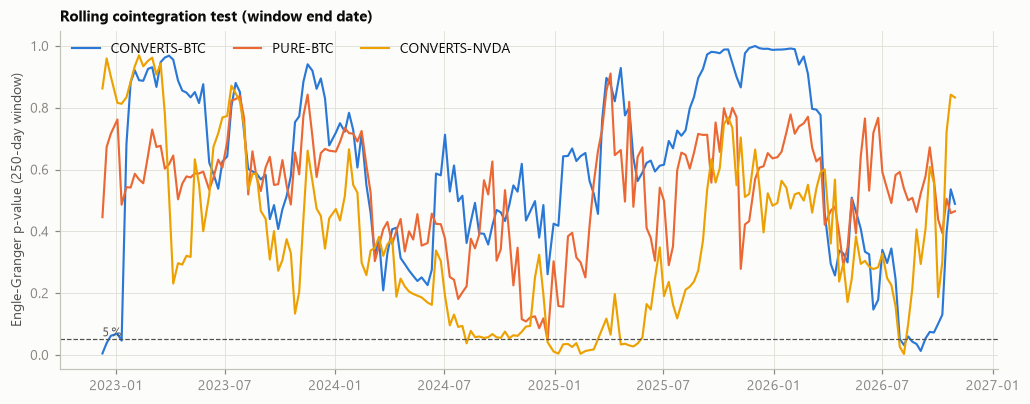

share of windows with p < 0.05: {'CONVERTS-BTC': 0.036, 'PURE-BTC': 0.005, 'CONVERTS-NVDA': 0.097}
            CONVERTS-BTC  PURE-BTC  CONVERTS-NVDA
2022-12-31         0.038     0.673          0.901
2023-03-31         0.889     0.603          0.907
2023-06-30         0.841     0.583          0.459
2023-09-30         0.594     0.641          0.585
2023-12-31         0.801     0.654          0.408
2024-03-31         0.607     0.658          0.382
2024-06-30         0.285     0.401          0.201
2024-09-30         0.469     0.345          0.068
2024-12-31         0.464     0.125          0.075
2025-03-31         0.643     0.390          0.030
2025-06-30         0.633     0.591          0.061
2025-09-30         0.798     0.648          0.237
2025-12-31         0.988     0.636          0.549
2026-03-31         0.953     0.694          0.532
2026-06-30         0.327     0.493          0.290
2026-09-30         0.060     0.539          0.248
2026-12-31         0.395     0.459          0.721


In [19]:
# Rolling Engle-Granger (H0: NO cointegration on that 1-year window); PURE-BTC is the control pair.
eg = pd.DataFrame({f"{a}-{b}": eda.rolling_engle_granger(logp[a], logp[b], window=250, step=5)
                   for a, b in [("CONVERTS", "BTC"), ("PURE", "BTC"), ("CONVERTS", "NVDA")]})
eg.to_csv(RES / "02_rolling_engle_granger.csv")
fig, ax = plt.subplots(figsize=(11, 4))
for c, col in zip(eg.columns, [plotting.CORE["CONVERTS"], plotting.CORE["PURE"], plotting.CORE["NVDA"]]):
    ax.plot(eg.index, eg[c], color=col, label=c)
ax.axhline(0.05, color=plotting.INK2, lw=0.8, ls="--"); ax.text(eg.index[0], 0.06, "5 %", fontsize=8, color=plotting.INK2)
ax.set_ylabel("Engle-Granger p-value (250-day window)"); ax.legend(loc="upper left", ncol=3)
ax.set_title("Rolling cointegration test (window end date)")
print(plotting.save(fig, "fig_02_11_rolling_engle_granger")); plt.show()
print("share of windows with p < 0.05:", (eg < 0.05).mean().round(3).to_dict())
print(eg.resample("QE").median().round(3).loc["2022-12":])

**Reading evidence 1 and 2.**

* **Correlation with BTC (fig. 02_10, left).** PURE stays tied to BTC almost all the time (≈ 0.4 to 0.77, mostly above 0.6). CONVERTS is always **below** PURE, but the CONVERTS − PURE gap widens clearly from summer 2025: −0.10 (end of June 2025) → −0.27 (end of September 2025) → −0.31 (end of December 2025). CONVERTS~BTC falls to 0.31 at the end of 2025 and is still 0.32 at the end of the sample. This is the most visible sign of a decoupling **specific to the converts**.
* **Correlation with NVDA (fig. 02_10, right).** Both groups follow **the same wave**: strong in 2022, near zero in 2023–2024, a peak in mid-2025 (CONVERTS 0.65, PURE 0.55), then a fall. CONVERTS is above PURE from late 2024 to mid-2025 (gap +0.06 to +0.15), then the gap returns towards 0. The link with NVDA is therefore **not exclusive** to the converts: the 2025 AI enthusiasm also carried the pure miners. Not to be over-interpreted.
* **Rolling Engle-Granger (fig. 02_11).** H0: no cointegration on the one-year window. H0 is rejected in only 3.6% of windows for CONVERTS–BTC, 0.5% for PURE–BTC (the control!) and 9.7% for CONVERTS–NVDA. Over one year, cointegration is almost never found, **even for the pure miners with BTC**. The CONVERTS–BTC p-value rises to ≈ 0.99 at the end of 2025, but since the control is not cointegrated either, this tool **does not discriminate** between the groups (low power on 250 observations). The lowest CONVERTS–NVDA p-values (median 0.03 for windows ending in Q1 2025) are a hint, not proof. Warning for Phase 4: hypothesis H1 ("PURE cointegrated with BTC") is not supported on rolling windows; it must be tested on the full sample.

In [20]:
# Bai-Perron style multiple breaks; the BIC picks the number. The CONVERTS-PURE spread removes the common 'miner' factor.
def X_of(cols):
    return pd.DataFrame({"const": 1.0, **{c: ret[c] for c in cols}}, index=ret.index)
SPECS = {"CONVERTS ~ BTC": (ret["CONVERTS"], ["BTC"]), "CONVERTS ~ BTC + NVDA": (ret["CONVERTS"], ["BTC", "NVDA"]),
         "PURE ~ BTC": (ret["PURE"], ["BTC"]), "PURE ~ BTC + NVDA": (ret["PURE"], ["BTC", "NVDA"]),
         "CONVERTS−PURE ~ BTC + NVDA": (ret["CONVERTS"] - ret["PURE"], ["BTC", "NVDA"])}
bp_all = []
for name, (y, cols) in SPECS.items():
    t = eda.bai_perron_ruptures(y, X_of(cols), max_breaks=3, min_size=60)
    bp_all.append(t.assign(spec=name, selected=t["BIC"] == t["BIC"].min()))
bp_all = pd.concat(bp_all, ignore_index=True)[["spec", "n_breaks", "SSR", "BIC", "selected", "break_dates"]]
bp_all.to_csv(RES / "02_breaks_bai_perron_full.csv", index=False)
bp_all

,spec,n_breaks,SSR,BIC,selected,break_dates
0,CONVERTS ~ BTC,0,3.6973,-7087.7624,True,[]
1,CONVERTS ~ BTC,1,3.6421,-7084.8527,False,[2022-06-30]
2,CONVERTS ~ BTC,2,3.6200,-7070.9749,False,"[2022-09-27, 2024-02-27]"
3,CONVERTS ~ BTC,3,3.5841,-7061.8252,False,"[2022-09-27, 2025-08-13, 2025-11-06]"
4,CONVERTS ~ BTC + NVDA,0,3.4424,-7168.0923,False,[]
5,CONVERTS ~ BTC + NVDA,1,3.3570,-7170.3966,True,[2022-09-27]
6,CONVERTS ~ BTC + NVDA,2,3.2821,-7169.5786,False,"[2022-10-18, 2025-01-22]"
7,CONVERTS ~ BTC + NVDA,3,3.2370,-7158.0647,False,"[2022-11-21, 2024-02-27, 2024-09-03]"
8,PURE ~ BTC,0,2.4416,-7595.6538,True,[]
9,PURE ~ BTC,1,2.4218,-7584.2901,False,[2022-06-17]


In [21]:
# The full-sample BIC break of CONVERTS ~ BTC + NVDA marks an early 'newly listed' regime; we look for a SECOND break after it
# (sequential logic of Bai-Perron: test l+1 breaks given l).
first_break = bp_all.query("spec == 'CONVERTS ~ BTC + NVDA' and selected")["break_dates"].iloc[0][0]
sub = ret.loc[first_break:]
def Xs_of(cols):
    return pd.DataFrame({"const": 1.0, **{c: sub[c] for c in cols}}, index=sub.index)
scan_specs = {"CONVERTS ~ BTC": ("CONVERTS", ["BTC"]), "CONVERTS ~ BTC + NVDA": ("CONVERTS", ["BTC", "NVDA"]),
              "PURE ~ BTC": ("PURE", ["BTC"]), "PURE ~ BTC + NVDA": ("PURE", ["BTC", "NVDA"])}
scans, scan_rows = {}, []
for name, (y, cols) in scan_specs.items():
    sc = eda.chow_scan(sub[y], Xs_of(cols))
    scans[name] = sc
    bp = eda.bai_perron_ruptures(sub[y], Xs_of(cols), max_breaks=3, min_size=60)
    scan_rows.append({"spec": name, "sample": f"{first_break} -> end", "sup_F": sc.max(), "date_sup_F": sc.idxmax().date(),
                      "p_chow_naive": eda.chow_test(sub[y], Xs_of(cols), sc.idxmax())["p_value"],
                      "BIC_n_breaks": int(bp.loc[bp["BIC"].idxmin(), "n_breaks"]),
                      "breaks_2_free": bp.loc[2, "break_dates"]})
scan_tab = pd.DataFrame(scan_rows)
scan_tab.to_csv(RES / "02_chow_scan_subsample.csv", index=False)
print("first (early) break:", first_break)
scan_tab

first (early) break: 2022-09-27


,spec,sample,sup_F,date_sup_F,p_chow_naive,BIC_n_breaks,breaks_2_free
0,CONVERTS ~ BTC,2022-09-27 -> end,3.7075,2024-02-27,2.4868e-02,0,"[2025-08-13, 2025-11-06]"
1,CONVERTS ~ BTC + NVDA,2022-09-27 -> end,8.6345,2025-01-22,1.1603e-05,0,"[2024-02-27, 2024-09-03]"
2,PURE ~ BTC,2022-09-27 -> end,4.9214,2024-02-27,7.4626e-03,0,"[2024-02-27, 2024-08-16]"
3,PURE ~ BTC + NVDA,2022-09-27 -> end,3.7978,2024-02-27,1.0042e-02,0,"[2023-03-20, 2024-02-27]"


figures\fig_02_12_chow_scan.png


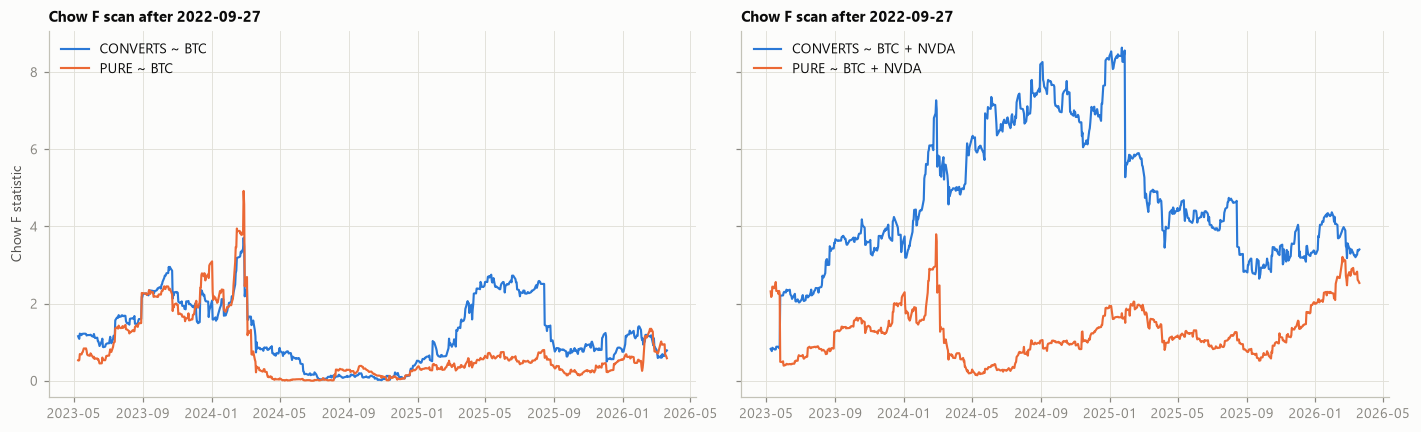

In [22]:
# Chow F curves: a converts-specific pivot should show a peak for CONVERTS that the PURE control does not have.
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, spec_set in zip(axes, (["CONVERTS ~ BTC", "PURE ~ BTC"], ["CONVERTS ~ BTC + NVDA", "PURE ~ BTC + NVDA"])):
    for name in spec_set:
        g = name.split()[0]
        ax.plot(scans[name].index, scans[name], color=plotting.CORE[g], label=name)
    ax.set_title(f"Chow F scan after {first_break}"); ax.legend(loc="upper left")
axes[0].set_ylabel("Chow F statistic")
fig.tight_layout(); print(plotting.save(fig, "fig_02_12_chow_scan")); plt.show()

In [23]:
# Candidate pivot dates, all produced by the code above (none typed from the news).
spread_bp = bp_all.query("spec == 'CONVERTS−PURE ~ BTC + NVDA' and selected")["break_dates"].iloc[0]
cand = {
    "A: BIC break of the CONVERTS−PURE spread": spread_bp[0] if spread_bp else None,
    "B: sup-F CONVERTS ~ BTC + NVDA (after 1st break)": str(scan_tab.set_index("spec").loc["CONVERTS ~ BTC + NVDA", "date_sup_F"]),
    "C: 1st of 2 free breaks CONVERTS ~ BTC": scan_tab.set_index("spec").loc["CONVERTS ~ BTC", "breaks_2_free"][0],
}
print(cand)
# Chow test at each candidate for CONVERTS and for the PURE control, on the post-early-regime sample.
XX = Xs_of(["BTC", "NVDA"])
rows = []
for lab, d in cand.items():
    for g in ("CONVERTS", "PURE"):
        c = eda.chow_test(sub[g], XX, d)
        rows.append({"candidate": lab, "date": d, "series": g, "F": c["F"], "p_value": c["p_value"], "n_before": c["n_before"], "n_after": c["n_after"]})
    # robustness: the same test without the single most extreme day of the period (DeepSeek, 2025-01-27)
    s2 = sub.drop(pd.Timestamp("2025-01-27"))
    c = eda.chow_test(s2["CONVERTS"], XX.drop(pd.Timestamp("2025-01-27")), d)
    rows.append({"candidate": lab, "date": d, "series": "CONVERTS without 2025-01-27", "F": c["F"], "p_value": c["p_value"], "n_before": c["n_before"], "n_after": c["n_after"]})
chow_c = pd.DataFrame(rows)
chow_c.to_csv(RES / "02_chow_candidates.csv", index=False)
chow_c.round(5)

{'A: BIC break of the CONVERTS−PURE spread': '2024-02-27', 'B: sup-F CONVERTS ~ BTC + NVDA (after 1st break)': '2025-01-22', 'C: 1st of 2 free breaks CONVERTS ~ BTC': '2025-08-13'}


,candidate,date,series,F,p_value,n_before,n_after
0,A: BIC break of the CONVERTS−PURE spread,2024-02-27,CONVERTS,7.2692,8.0000e-05,355,673
1,A: BIC break of the CONVERTS−PURE spread,2024-02-27,PURE,3.7978,1.0040e-02,355,673
2,A: BIC break of the CONVERTS−PURE spread,2024-02-27,CONVERTS without 2025-01-27,6.3810,2.8000e-04,355,672
3,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),2025-01-22,CONVERTS,8.6345,1.0000e-05,581,447
4,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),2025-01-22,PURE,1.7515,1.5481e-01,581,447
5,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),2025-01-22,CONVERTS without 2025-01-27,6.5187,2.3000e-04,581,446
6,C: 1st of 2 free breaks CONVERTS ~ BTC,2025-08-13,CONVERTS,4.6427,3.1300e-03,721,307
7,C: 1st of 2 free breaks CONVERTS ~ BTC,2025-08-13,PURE,1.2633,2.8566e-01,721,307
8,C: 1st of 2 free breaks CONVERTS ~ BTC,2025-08-13,CONVERTS without 2025-01-27,5.0571,1.7600e-03,720,307


In [24]:
# What changes at each candidate: OLS betas on BTC and NVDA per regime, CONVERTS vs PURE (correlations alongside).
reg = []
for lab, d in cand.items():
    for g in ("CONVERTS", "PURE"):
        t = eda.regime_betas(sub[g], XX, [d]).assign(candidate=lab, series=g)
        t["corr_BTC"] = [sub.loc[str(a):str(b), [g, "BTC"]].corr().iloc[0, 1] for a, b in zip(t["start"], t["end"])]
        t["corr_NVDA"] = [sub.loc[str(a):str(b), [g, "NVDA"]].corr().iloc[0, 1] for a, b in zip(t["start"], t["end"])]
        reg.append(t)
reg = pd.concat(reg, ignore_index=True)[["candidate", "series", "start", "end", "n", "beta_BTC", "beta_NVDA", "R2", "corr_BTC", "corr_NVDA"]]
reg.to_csv(RES / "02_regime_betas.csv", index=False)
reg.round(3)

,candidate,series,start,end,n,beta_BTC,beta_NVDA,R2,corr_BTC,corr_NVDA
0,A: BIC break of the CONVERTS−PURE spread,CONVERTS,2022-09-27,2024-02-26,355,1.206,0.265,0.332,0.564,0.241
1,A: BIC break of the CONVERTS−PURE spread,CONVERTS,2024-02-27,2026-10-30,673,0.763,0.662,0.304,0.458,0.422
2,A: BIC break of the CONVERTS−PURE spread,PURE,2022-09-27,2024-02-26,355,1.299,0.402,0.473,0.659,0.334
3,A: BIC break of the CONVERTS−PURE spread,PURE,2024-02-27,2026-10-30,673,0.995,0.371,0.419,0.616,0.362
4,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),CONVERTS,2022-09-27,2025-01-21,581,1.025,0.310,0.312,0.539,0.265
5,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),CONVERTS,2025-01-22,2026-10-30,447,0.707,0.867,0.327,0.427,0.493
6,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),PURE,2022-09-27,2025-01-21,581,1.149,0.323,0.438,0.642,0.304
7,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),PURE,2025-01-22,2026-10-30,447,1.008,0.494,0.442,0.611,0.438
8,C: 1st of 2 free breaks CONVERTS ~ BTC,CONVERTS,2022-09-27,2025-08-12,721,1.017,0.446,0.338,0.538,0.338
9,C: 1st of 2 free breaks CONVERTS ~ BTC,CONVERTS,2025-08-13,2026-10-30,307,0.602,0.844,0.235,0.381,0.415


**Summary of the evidence and proposal.**

| Evidence | Result | Specific to the converts? |
|---|---|---|
| Bai-Perron breaks, full sample | CONVERTS~BTC: BIC keeps **0** breaks; CONVERTS~BTC+NVDA: 1 break on **2022-09-27** (early-listing regime, β_BTC from 0.34 to ≈ 1) | no, this is not an AI pivot |
| Chow scan after 2022-09-27, CONVERTS~BTC | peak on 2024-02-27 (F = 3.71), but PURE has a **stronger peak on the same date** (F = 4.92) | no, it is a shock common to miners |
| Chow scan after 2022-09-27, CONVERTS~BTC+NVDA | **sup-F = 8.63 on 2025-01-22**; PURE has no break on that date (Chow F = 1.75, p = 0.15) | **yes** |
| Same test without the DeepSeek day (2025-01-27) | F = 6.52, p = 0.0002: the break does not rest on a single day | **yes** |
| CONVERTS − PURE spread ~ BTC + NVDA | BIC keeps 1 break on 2024-02-27 (β_NVDA of the spread goes from −0.21 to +0.29); but PURE also breaks on that date (p = 0.010) | partly |
| Two free breaks CONVERTS~BTC | 2025-08-13 and 2025-11-06; Chow at 2025-08-13: CONVERTS p = 0.003, PURE p = 0.29; coincides with the TeraWulf–Google deal and the decoupling of correlations | yes, but BIC does not keep it |

**What changes on 2025-01-22** (`02_regime_betas.csv`):
* CONVERTS: β_BTC goes from 1.03 to 0.71, β_NVDA from 0.31 to 0.87; correlation with BTC from 0.54 to 0.43, with NVDA from 0.27 to 0.49.
* PURE, on the same date: β_BTC from 1.15 to 1.01, β_NVDA from 0.32 to 0.49. The move goes in the same direction but is much weaker, and it is not significant.

**Limits to keep in mind.**
* The Chow p-values are "naive": the date was chosen by looking at the data, so the true significance is lower. The correct threshold would be Andrews' for a sup-F.
* In the sub-sample, BIC does not keep a second break for CONVERTS: the evidence for a **clean, single** break is **moderate**.
* The transition looks more like a two-step shift: sensitivities change in early 2025, then correlations and levels decouple from August 2025.

**Chosen pivot: 2025-01-22 (candidate B)**, validated by the student on 2026-11-12 and saved in `config.yaml`. Reasons:
1. It is the only date where the converts' relationship changes **without** the PURE control changing.
2. The direction of the change is that of H2: less BTC, more NVDA.
3. The result survives removing the most extreme day.
4. It leaves 324 post-pivot training observations, enough for a post-pivot VAR or VECM in Phase 4 (candidate C leaves only 184).

Candidates A (2024-02-27) and C (2025-08-13) are used as **robustness checks** in Phase 4.

In [25]:
# The pivot is written to config.yaml ONLY after the student validated it (set APPROVED_PIVOT, then re-run).
APPROVED_PIVOT = "2025-01-22"   # validated by the student on 2026-11-12 (candidate B)
if APPROVED_PIVOT is not None:
    config.update_pivot(APPROVED_PIVOT)
PIVOT = config.load_config()["pivot_date"]
print("pivot_date in config.yaml:", PIVOT)

pivot_date in config.yaml: 2025-01-22


## 7. Train / test split (90 / 10 chronological)

The dates come from `config.yaml` (written in Phase 1) and are recomputed here to check that they have not moved.

In [26]:
# Recompute the split and assert it matches config.yaml, so Python and R keep the same test set.
sp = cfg["split"]
assert (len(train), len(test)) == (sp["n_train"], sp["n_test"])
assert str(train.index[-1].date()) == sp["train_end"] and str(test.index[0].date()) == sp["test_start"]
print(f"train: {len(train)} obs, {train.index[0].date()} -> {train.index[-1].date()}")
print(f"test : {len(test)} obs, {test.index[0].date()} -> {test.index[-1].date()}")
# Where each candidate pivot falls relative to the test set.
pos = pd.DataFrame([{"candidate": lab, "date": d,
                     "train obs before pivot": int((train.index < pd.Timestamp(d)).sum()),
                     "train obs after pivot": int((train.index >= pd.Timestamp(d)).sum()),
                     "test entirely after pivot": test.index[0] >= pd.Timestamp(d)} for lab, d in cand.items()])
pos

train: 1102 obs, 2021-12-14 -> 2026-05-06
test : 123 obs, 2026-05-07 -> 2026-10-30


,candidate,date,train obs before pivot,train obs after pivot,test entirely after pivot
0,A: BIC break of the CONVERTS−PURE spread,2024-02-27,552,550,True
1,B: sup-F CONVERTS ~ BTC + NVDA (after 1st break),2025-01-22,778,324,True
2,C: 1st of 2 free breaks CONVERTS ~ BTC,2025-08-13,918,184,True


figures\fig_02_13_split_and_pivot.png


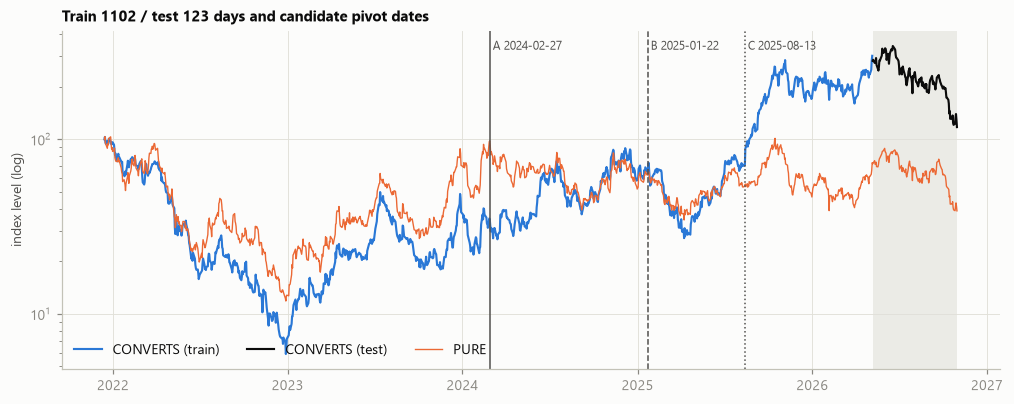

In [27]:
# Split plot with the candidate pivots, so the reader sees which regime the test set belongs to.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index, train["CONVERTS_level"], color=plotting.CORE["CONVERTS"], label="CONVERTS (train)")
ax.plot(test.index, test["CONVERTS_level"], color=plotting.INK, label="CONVERTS (test)")
ax.plot(panel.index, panel["PURE_level"], color=plotting.CORE["PURE"], lw=0.9, label="PURE")
ax.axvspan(test.index[0], test.index[-1], color=plotting.GRID, alpha=0.6, lw=0)
for (lab, d), ls in zip(cand.items(), ["-", "--", ":"]):
    ax.axvline(pd.Timestamp(d), color=plotting.INK2, lw=1, ls=ls)
    ax.text(pd.Timestamp(d), 0.97, f" {lab[0]} {d}", transform=ax.get_xaxis_transform(), fontsize=8, color=plotting.INK2, va="top")
ax.set_yscale("log"); ax.set_ylabel("index level (log)"); ax.legend(loc="lower left", ncol=3)
ax.set_title(f"Train {len(train)} / test {len(test)} days and candidate pivot dates")
print(plotting.save(fig, "fig_02_13_split_and_pivot")); plt.show()

**Split.** Train: 1,102 days (2021-12-14 → 2026-05-06). Test: 123 days (2026-05-07 → 2026-10-30). The dates are identical to those in `config.yaml`.

**Position of the pivot.** All three candidates fall **before** the test sample: the test lies entirely in the post-pivot regime. Two consequences:
1. The forecast comparisons (Phase 7) measure performance in the **new** regime only.
2. A model estimated on the whole training sample mixes two regimes, which is a limitation to discuss. With candidate B, the training sample has 778 observations before the pivot and 324 after.

The test also covers a particular phase: CONVERTS first rises, then falls sharply at the end of the period (fig. 02_13).

## Phase 2 summary

1. **Stationarity.** Log prices are I(1) and returns I(0) for all ten series; ADF and KPSS agree, except WULF and RIOT in level (ambiguous cases, d = 1 kept).
2. **Autocorrelation and volatility.** The returns of CONVERTS, PURE and BTC have no autocorrelation (Ljung-Box not rejected), hence an expected ARIMA(0,1,0). Squared returns are autocorrelated for PURE, BTC and NVDA, which justifies GARCH; not for CONVERTS, to be re-checked with ARCH-LM.
3. **Seasonality.** No real seasonality: F_S ≤ 0.03 for s = 5, ≈ 0 for s = 252; no day-of-week effect (p ≥ 0.09).
4. **Outliers.** They are kept: they are real market events, linked to identified shocks (FTX, DeepSeek, the Google deal…).
5. **Pivot.** The best date specific to the converts is **2025-01-22**: β_BTC goes from 1.03 to 0.71 and β_NVDA from 0.31 to 0.87, with no break for PURE. The decoupling of correlations with BTC is visible mainly from August 2025. The evidence is moderate (naive p-values, not kept by BIC in the sub-sample).